# PROJET F16 – LOI D'OKUN

**Étude de la relation entre la croissance économique et le chômage aux États-Unis**

- **Étudiant :** Bakary Traoré
- **Code Apogée :** 26006200
- **Groupe :** FIN G3
- **Pays étudié :** États-Unis
- **Source des données :** FRED – Federal Reserve Bank of St. Louis
- **Environnement :** Python / Google Colab

---

## 1. Sujet et problématique

### Intérêt du sujet

La relation entre la croissance économique et le chômage constitue un enjeu important de la politique économique. La Loi d'Okun permet d'étudier le lien entre l'évolution de l'activité économique et celle du chômage.

### Problématique

Dans quelle mesure la croissance économique suffit-elle à réduire durablement le chômage aux États-Unis ?

### Objectif du projet

Étudier la relation statistique entre la croissance trimestrielle du PIB réel et la variation trimestrielle du taux de chômage aux États-Unis, puis examiner la stabilité de cette relation dans le temps.

### Nature du problème

Régression supervisée : expliquer la variation du taux de chômage à partir de la croissance du PIB réel, au moyen d'une régression linéaire simple.

## 2. Jeu de données

### 2.1. Sources des données

Les données utilisées dans cette étude proviennent de FRED (Federal Reserve Bank of St. Louis).

Deux séries économiques sont exploitées :

- **GDPC1 :** produit intérieur brut réel des États-Unis, à fréquence trimestrielle.
- **UNRATE :** taux de chômage des États-Unis, à fréquence mensuelle.

### 2.2. Période d'étude

L'étude couvre la période allant du premier trimestre 1990 au troisième trimestre 2026, selon les observations disponibles dans les fichiers téléchargés.

### 2.3. Variables utilisées

| Variable | Description | Unité |
|---|---|---|
| GDPC1 | PIB réel | Milliards de dollars chaînés |
| UNRATE | Taux de chômage | Pourcentage |
| GDP_Growth | Croissance trimestrielle annualisée du PIB réel | Pourcentage |
| Delta_UNRATE | Variation trimestrielle du taux de chômage | Points de pourcentage |

### 2.4. Qualité et limites initiales des données

Les deux séries présentent des fréquences différentes : le PIB est trimestriel tandis que le taux de chômage est mensuel.

Une agrégation du chômage par moyenne trimestrielle est donc nécessaire.

Une valeur manquante a été identifiée pour octobre 2025. Le quatrième trimestre 2025 sera considéré comme incomplet et ne sera pas utilisé pour calculer la variation trimestrielle du chômage.

In [133]:

from importlib.metadata import version

bibliotheques = [
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "statsmodels"
]

print("VERSIONS DES BIBLIOTHÈQUES")
for bibliotheque in bibliotheques:
    print(f"{bibliotheque}=={version(bibliotheque)}")


VERSIONS DES BIBLIOTHÈQUES
pandas==2.2.3
numpy==2.4.6
matplotlib==3.10.0
seaborn==0.13.2
scikit-learn==1.6.1
statsmodels==0.15.0


In [134]:

from pathlib import Path

# Rechercher les fichiers CSV importés dans Colab
fichiers_csv = list(Path("/content").glob("*.csv"))

# Afficher les noms des fichiers trouvés
for fichier in fichiers_csv:
    print(fichier.name)


PIB REEL USA trimestriel.csv
TAUX DE CHOMAGE DE USA mensuel.csv


In [135]:

import pandas as pd

# Charger les deux fichiers CSV
chomage = pd.read_csv("/content/TAUX DE CHOMAGE DE USA mensuel.csv")
pib = pd.read_csv("/content/PIB REEL USA trimestriel.csv")

# Afficher les cinq premières observations
print("TAUX DE CHÔMAGE")
display(chomage.head())

print("PIB RÉEL")
display(pib.head())


TAUX DE CHÔMAGE


,observation_date,UNRATE
0,1948-01-01,3.4
1,1948-02-01,3.8
2,1948-03-01,4.0
3,1948-04-01,3.9
4,1948-05-01,3.5


PIB RÉEL


,observation_date,GDPC1
0,1947-01-01,2182.681
1,1947-04-01,2176.892
2,1947-07-01,2172.432
3,1947-10-01,2206.452
4,1948-01-01,2239.682


In [136]:

# Convertir les dates au format datetime
chomage["observation_date"] = pd.to_datetime(chomage["observation_date"])
pib["observation_date"] = pd.to_datetime(pib["observation_date"])

# Vérifier les dimensions des deux tableaux
print("DIMENSIONS DES DONNÉES")
print("Chômage :", chomage.shape)
print("PIB :", pib.shape)

# Vérifier les périodes disponibles
print("\nPÉRIODES COUVERTES")
print("Chômage :", chomage["observation_date"].min(),
      "à", chomage["observation_date"].max())
print("PIB :", pib["observation_date"].min(),
      "à", pib["observation_date"].max())

# Vérifier les valeurs manquantes
print("\nVALEURS MANQUANTES")
print(chomage.isna().sum())
print(pib.isna().sum())

# Vérifier les types de données
print("\nTYPES DE DONNÉES")
print(chomage.dtypes)
print(pib.dtypes)


DIMENSIONS DES DONNÉES
Chômage : (946, 2)
PIB : (319, 2)

PÉRIODES COUVERTES
Chômage : 1948-01-01 00:00:00 à 2026-10-01 00:00:00
PIB : 1947-01-01 00:00:00 à 2026-07-01 00:00:00

VALEURS MANQUANTES
observation_date    0
UNRATE              1
dtype: int64
observation_date    0
GDPC1               0
dtype: int64

TYPES DE DONNÉES
observation_date    datetime64[ns]
UNRATE                     float64
dtype: object
observation_date    datetime64[ns]
GDPC1                      float64
dtype: object


In [137]:

# Examiner les premières valeurs du PIB
print("Premières valeurs du PIB :")
print(pib["GDPC1"].head(10).tolist())

# Examiner le format des valeurs
print("\nType de la première valeur :")
print(type(pib["GDPC1"].iloc[0]))

# Identifier les valeurs qui ne sont pas numériques
pib_test = pd.to_numeric(pib["GDPC1"], errors="coerce")

print("\nNombre de valeurs devenues manquantes après conversion :")
print(pib_test.isna().sum())


Premières valeurs du PIB :
[2182.681, 2176.892, 2172.432, 2206.452, 2239.682, 2276.69, 2289.77, 2292.364, 2260.807, 2253.128]

Type de la première valeur :
<class 'numpy.float64'>

Nombre de valeurs devenues manquantes après conversion :
0


In [138]:

# Convertir la colonne du PIB en valeurs numériques
pib["GDPC1"] = pd.to_numeric(pib["GDPC1"])

# Vérifier les types après conversion
print("Types des colonnes du PIB :")
print(pib.dtypes)

# Vérifier les valeurs manquantes
print("\nValeurs manquantes :")
print(pib.isna().sum())


Types des colonnes du PIB :
observation_date    datetime64[ns]
GDPC1                      float64
dtype: object

Valeurs manquantes :
observation_date    0
GDPC1               0
dtype: int64


In [139]:

# Définir les bornes de la période d'étude
date_debut = "1990-01-01"
date_fin = "2026-09-30"

# Créer des copies limitées à la période choisie
chomage_1990 = chomage[
    (chomage["observation_date"] >= date_debut) &
    (chomage["observation_date"] <= date_fin)
].copy()

pib_1990 = pib[
    (pib["observation_date"] >= date_debut) &
    (pib["observation_date"] <= date_fin)
].copy()

# Vérifier les dimensions
print("Nombre d'observations après sélection :")
print("Chômage :", chomage_1990.shape)
print("PIB :", pib_1990.shape)

# Vérifier les dates
print("\nPériode du chômage :")
print(chomage_1990["observation_date"].min(),
      "à", chomage_1990["observation_date"].max())

print("\nPériode du PIB :")
print(pib_1990["observation_date"].min(),
      "à", pib_1990["observation_date"].max())


Nombre d'observations après sélection :
Chômage : (441, 2)
PIB : (147, 2)

Période du chômage :
1990-01-01 00:00:00 à 2026-09-01 00:00:00

Période du PIB :
1990-01-01 00:00:00 à 2026-07-01 00:00:00


Transformer le chômage mensuel en chômage trimestriel

In [140]:

# Identifier le trimestre de chaque observation mensuelle
chomage_1990["trimestre"] = (
    chomage_1990["observation_date"].dt.to_period("Q")
)

# Calculer le nombre de mois disponibles et la moyenne trimestrielle
chomage_trimestriel = (
    chomage_1990.groupby("trimestre")
    .agg(
        nb_mois=("UNRATE", "count"),
        taux_chomage=("UNRATE", "mean")
    )
    .reset_index()
)

# Ne conserver la moyenne que si les trois mois sont disponibles
chomage_trimestriel.loc[
    chomage_trimestriel["nb_mois"] < 3,
    "taux_chomage"
] = pd.NA

# Afficher les résultats
print("Nombre de trimestres :", len(chomage_trimestriel))

print("\nTrimestres incomplets :")
display(
    chomage_trimestriel[
        chomage_trimestriel["nb_mois"] < 3
    ]
)

print("\nPremières observations trimestrielles :")
display(chomage_trimestriel.head())


Nombre de trimestres : 147

Trimestres incomplets :


,trimestre,nb_mois,taux_chomage
143,2025Q4,2,NaN



Premières observations trimestrielles :


,trimestre,nb_mois,taux_chomage
0,1990Q1,3,5.300000
1,1990Q2,3,5.333333
2,1990Q3,3,5.700000
3,1990Q4,3,6.133333
4,1991Q1,3,6.600000


Préparer la fusion des deux séries

In [141]:

# Créer une variable trimestrielle pour le PIB
pib_1990["trimestre"] = (
    pib_1990["observation_date"].dt.to_period("Q")
)

# Renommer la colonne du PIB
pib_1990 = pib_1990.rename(
    columns={"GDPC1": "PIB_reel"}
)

# Fusionner les deux séries sur le trimestre
donnees = pd.merge(
    pib_1990[["trimestre", "PIB_reel"]],
    chomage_trimestriel[
        ["trimestre", "taux_chomage"]
    ],
    on="trimestre",
    how="inner"
)

# Trier les observations chronologiquement
donnees = donnees.sort_values("trimestre").reset_index(drop=True)

# Afficher les résultats
print("Dimensions du tableau fusionné :", donnees.shape)

print("\nPremières observations :")
display(donnees.head())

print("\nDernières observations :")
display(donnees.tail())

print("\nValeurs manquantes :")
print(donnees.isna().sum())


Dimensions du tableau fusionné : (147, 3)

Premières observations :


,trimestre,PIB_reel,taux_chomage
0,1990Q1,10047.386,5.300000
1,1990Q2,10083.855,5.333333
2,1990Q3,10090.569,5.700000
3,1990Q4,9998.704,6.133333
4,1991Q1,9951.916,6.600000



Dernières observations :


,trimestre,PIB_reel,taux_chomage
142,2025Q3,24112.966,4.333333
143,2025Q4,24125.479,NaN
144,2026Q1,24274.383,4.333333
145,2026Q2,24408.011,4.266667
146,2026Q3,24611.077,4.133333



Valeurs manquantes :
trimestre       0
PIB_reel        0
taux_chomage    1
dtype: int64


**Calculer les deux variables économiques**

Pour étudier la loi d'Okun, nous avons besoin de deux nouvelles variables :
1. La croissance trimestrielle non annualisée du PIB réel.
2. La variation trimestrielle du taux de chômage, exprimée en points de pourcentage.

In [142]:

# Calculer la croissance trimestrielle non annualisée du PIB réel
donnees["GDP_Growth"] = (
    (donnees["PIB_reel"] / donnees["PIB_reel"].shift(1) - 1) * 100
)

# Calculer la variation trimestrielle du taux de chômage
donnees["Delta_UNRATE"] = donnees["taux_chomage"].diff()

# Afficher les premières observations
print("Premières observations après calcul :")
display(donnees.head(10))

# Afficher les dernières observations
print("\nDernières observations :")
display(donnees.tail(10))

# Vérifier les valeurs manquantes
print("\nValeurs manquantes :")
print(donnees.isna().sum())


Premières observations après calcul :


,trimestre,PIB_reel,taux_chomage,GDP_Growth,Delta_UNRATE
0,1990Q1,10047.386,5.300000,NaN,NaN
1,1990Q2,10083.855,5.333333,0.362970,0.033333
2,1990Q3,10090.569,5.700000,0.066582,0.366667
3,1990Q4,9998.704,6.133333,-0.910405,0.433333
4,1991Q1,9951.916,6.600000,-0.467941,0.466667
5,1991Q2,10029.510,6.833333,0.779689,0.233333
6,1991Q3,10080.195,6.866667,0.505359,0.033333
7,1991Q4,10115.329,7.100000,0.348545,0.233333
8,1992Q1,10236.435,7.366667,1.197252,0.266667
9,1992Q2,10347.429,7.600000,1.084303,0.233333



Dernières observations :


,trimestre,PIB_reel,taux_chomage,GDP_Growth,Delta_UNRATE
137,2024Q2,23320.074,3.966667,0.882935,1.333333e-01
138,2024Q3,23501.760,4.166667,0.779097,2.000000e-01
139,2024Q4,23641.759,4.133333,0.595696,-3.333333e-02
140,2025Q1,23650.213,4.133333,0.035759,8.881784e-16
141,2025Q2,23884.563,4.200000,0.990900,6.666667e-02
142,2025Q3,24112.966,4.333333,0.956279,1.333333e-01
143,2025Q4,24125.479,NaN,0.051893,NaN
144,2026Q1,24274.383,4.333333,0.617206,NaN
145,2026Q2,24408.011,4.266667,0.550490,-6.666667e-02
146,2026Q3,24611.077,4.133333,0.831965,-1.333333e-01



Valeurs manquantes :
trimestre       0
PIB_reel        0
taux_chomage    1
GDP_Growth      1
Delta_UNRATE    3
dtype: int64


**Construire le jeu de données final**

In [143]:

# Créer le jeu de données final
donnees_finales = donnees.dropna(
    subset=["GDP_Growth", "Delta_UNRATE"]
).copy()

# Vérifier les dimensions
print("Dimensions du jeu de données final :")
print(donnees_finales.shape)

# Vérifier les valeurs manquantes
print("\nValeurs manquantes :")
print(donnees_finales.isna().sum())

# Afficher les premières et dernières observations
print("\nPremières observations :")
display(donnees_finales.head())

print("\nDernières observations :")
display(donnees_finales.tail())


Dimensions du jeu de données final :
(144, 5)

Valeurs manquantes :
trimestre       0
PIB_reel        0
taux_chomage    0
GDP_Growth      0
Delta_UNRATE    0
dtype: int64

Premières observations :


,trimestre,PIB_reel,taux_chomage,GDP_Growth,Delta_UNRATE
1,1990Q2,10083.855,5.333333,0.362970,0.033333
2,1990Q3,10090.569,5.700000,0.066582,0.366667
3,1990Q4,9998.704,6.133333,-0.910405,0.433333
4,1991Q1,9951.916,6.600000,-0.467941,0.466667
5,1991Q2,10029.510,6.833333,0.779689,0.233333



Dernières observations :


,trimestre,PIB_reel,taux_chomage,GDP_Growth,Delta_UNRATE
140,2025Q1,23650.213,4.133333,0.035759,8.881784e-16
141,2025Q2,23884.563,4.200000,0.990900,6.666667e-02
142,2025Q3,24112.966,4.333333,0.956279,1.333333e-01
145,2026Q2,24408.011,4.266667,0.550490,-6.666667e-02
146,2026Q3,24611.077,4.133333,0.831965,-1.333333e-01


**Contrôle final**

In [144]:

# Vérifier l'ordre chronologique
print("Premier trimestre :", donnees_finales["trimestre"].min())
print("Dernier trimestre :", donnees_finales["trimestre"].max())

# Vérifier les doublons
print("\nNombre de doublons :")
print(donnees_finales["trimestre"].duplicated().sum())

# Vérifier les dimensions
print("\nDimensions :", donnees_finales.shape)

# Vérifier les valeurs manquantes
print("\nValeurs manquantes :")
print(donnees_finales.isna().sum())


Premier trimestre : 1990Q2
Dernier trimestre : 2026Q3

Nombre de doublons :
0

Dimensions : (144, 5)

Valeurs manquantes :
trimestre       0
PIB_reel        0
taux_chomage    0
GDP_Growth      0
Delta_UNRATE    0
dtype: int64


In [145]:

from pathlib import Path

# Créer le dossier des données préparées
dossier = Path("/content/data/processed")
dossier.mkdir(parents=True, exist_ok=True)

# Enregistrer le jeu de données final
chemin = dossier / "donnees_finales_F16.csv"
donnees_finales.to_csv(chemin, index=False)

print("Fichier enregistré :", chemin)
print("Taille du fichier :", donnees_finales.shape)


Fichier enregistré : /content/data/processed/donnees_finales_F16.csv
Taille du fichier : (144, 5)


**Analyse exploratoire des données (EDA)**

In [146]:
# 1. Importer les bibliothèques nécessaires
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Afficher les statistiques descriptives
donnees_finales.describe()

,PIB_reel,taux_chomage,GDP_Growth,Delta_UNRATE
count,144.000000,144.000000,144.000000,144.000000
mean,16481.899021,5.665046,0.625460,-0.008102
std,3990.211343,1.739555,1.099190,0.906227
min,9951.916000,3.533333,-7.876784,-4.200000
25%,13398.960250,4.325000,0.361884,-0.200000
50%,16572.288000,5.333333,0.671775,-0.066667
75%,19327.849750,6.608333,0.974412,0.066667
max,24611.077000,13.000000,7.762279,9.166667


**Construire les trois graphiques**

Graphique 1 — Évolution de la croissance du PIB



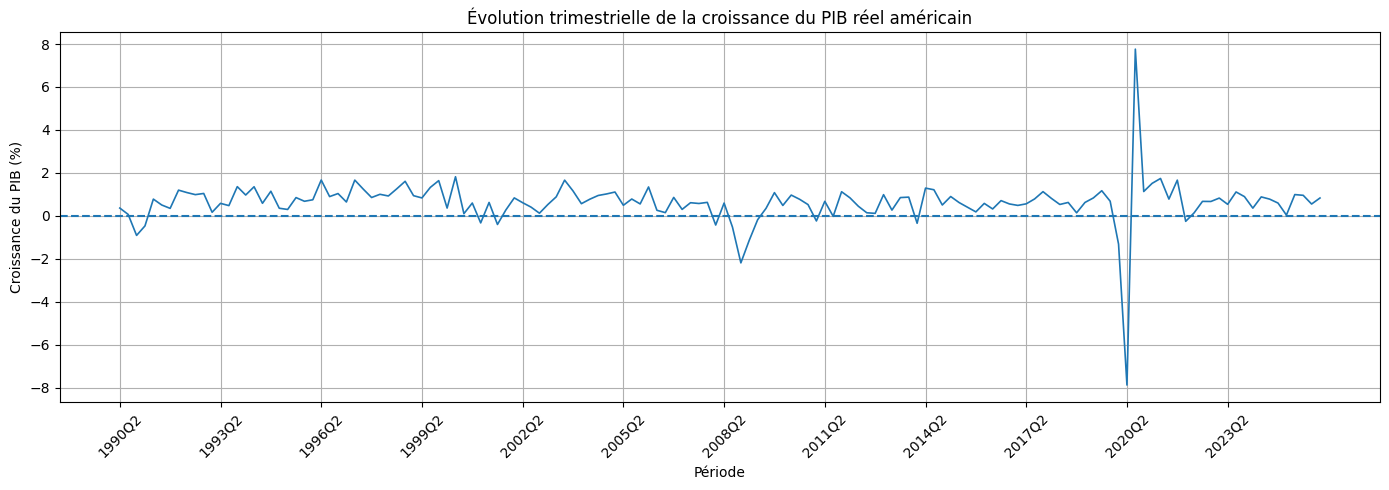

In [147]:
plt.figure(figsize=(14, 5))

plt.plot(
    range(len(donnees_finales)),
    donnees_finales["GDP_Growth"],
    linewidth=1.2
)

plt.axhline(y=0, linestyle="--")

plt.title("Évolution trimestrielle de la croissance du PIB réel américain")
plt.xlabel("Période")
plt.ylabel("Croissance du PIB (%)")

# Afficher une étiquette tous les 12 trimestres
positions = range(0, len(donnees_finales), 12)
etiquettes = donnees_finales["trimestre"].astype(str)

plt.xticks(
    positions,
    etiquettes.iloc[::12],
    rotation=45
)

plt.grid(True)
plt.tight_layout()
plt.show()

**Interprétation du graphique 1: croissance du PIB américain**

Le graphique présente l'évolution trimestrielle de la croissance du PIB réel américain entre 1990 et 2026. Il montre que la croissance économique est généralement positive, mais qu'elle connaît plusieurs épisodes de contraction. Les variations les plus importantes apparaissent autour de 2020, période marquée par la crise sanitaire liée à la COVID-19. Ces fluctuations illustrent l'instabilité de l'activité économique et permettront d'étudier son association avec les variations du chômage.




**Deuxième graphique — Évolution du taux de chômage américain**

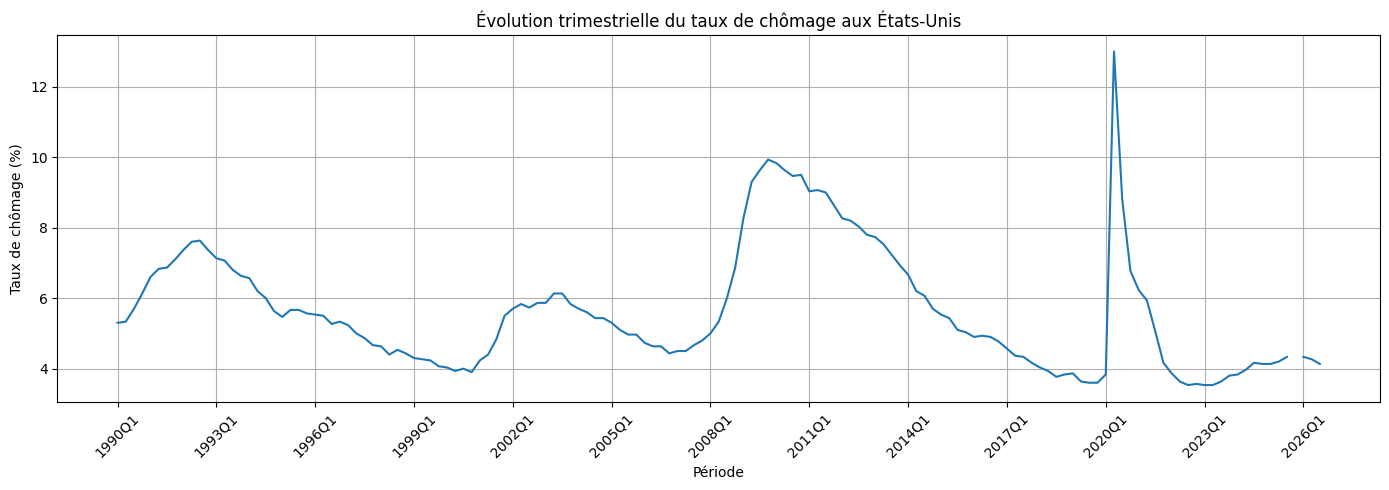

In [148]:
plt.figure(figsize=(14, 5))

plt.plot(
    range(len(chomage_trimestriel)),
    chomage_trimestriel["taux_chomage"],
    linewidth=1.5
)

plt.title("Évolution trimestrielle du taux de chômage aux États-Unis")
plt.xlabel("Période")
plt.ylabel("Taux de chômage (%)")

# Afficher une date tous les 12 trimestres
positions = range(0, len(chomage_trimestriel), 12)
etiquettes = chomage_trimestriel["trimestre"].astype(str)

plt.xticks(
    positions,
    etiquettes.iloc[::12],
    rotation=45
)

plt.grid(True)
plt.tight_layout()
plt.show()

**Interprétation du graphique 2: taux de chômage américain**

Le graphique présente l'évolution trimestrielle du taux de chômage aux États-Unis entre 1990 et 2026. Il met en évidence plusieurs épisodes de hausse importante du chômage, notamment lors de la crise financière de 2008 et de la crise sanitaire de 2020. Après ces périodes, le taux de chômage diminue progressivement. Ces évolutions montrent que le marché du travail américain est sensible aux fluctuations de l'activité économique.

**Troisième graphique — Relation entre croissance du PIB et variation du chômage**

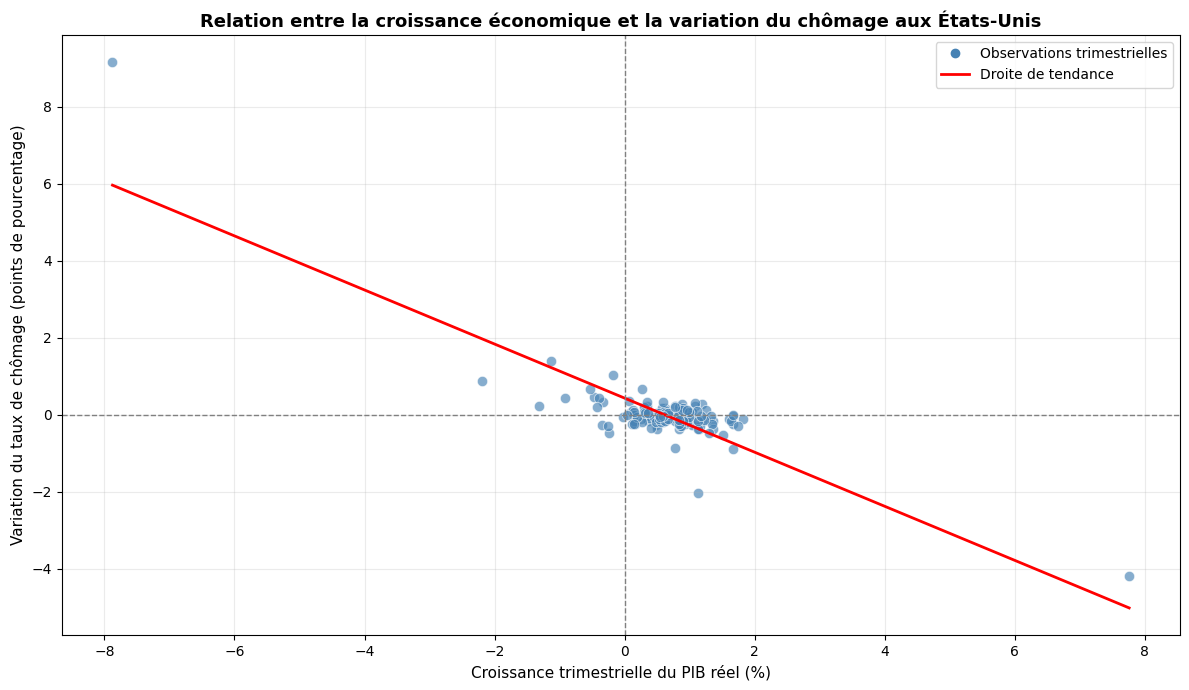

In [149]:
plt.figure(figsize=(12, 7))

# Nuage de points
sns.scatterplot(
    data=donnees_finales,
    x="GDP_Growth",
    y="Delta_UNRATE",
    label="Observations trimestrielles",
    color="steelblue",
    alpha=0.65,
    s=55
)

# Droite de tendance
sns.regplot(
    data=donnees_finales,
    x="GDP_Growth",
    y="Delta_UNRATE",
    scatter=False,
    ci=None,
    line_kws={
        "color": "red",
        "linewidth": 2,
        "label": "Droite de tendance"
    }
)


# Lignes de référence
plt.axhline(y=0, color="gray", linestyle="--", linewidth=1)
plt.axvline(x=0, color="gray", linestyle="--", linewidth=1)

# Titres et axes
plt.title(
    "Relation entre la croissance économique et la variation du chômage aux États-Unis",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Croissance trimestrielle du PIB réel (%)", fontsize=11)
plt.ylabel("Variation du taux de chômage (points de pourcentage)", fontsize=11)

# Légende
plt.legend(loc="upper right", fontsize=10)

# Présentation
plt.grid(alpha=0.25)
plt.tight_layout()
from matplotlib.lines import Line2D

plt.legend(handles=[
    Line2D([0], [0], marker="o", color="steelblue",
           linestyle="None", label="Observations trimestrielles"),
    Line2D([0], [0], color="red",
           linewidth=2, label="Droite de tendance")
])
plt.show()

**Interprétation économique du graphique 3: Relation entre croissance du PIB et variation du chômage**

Le nuage de points met en évidence une relation linéaire négative entre la croissance trimestrielle du PIB réel et la variation du taux de chômage aux États-Unis. La droite de tendance décroissante suggère que les périodes de croissance économique plus élevée sont généralement associées à une diminution de la variation du chômage. Toutefois, certaines observations atypiques sont éloignées du groupe principal. Cette relation descriptive ne permet pas, à elle seule, de conclure à un lien de causalité.

### Synthèse générale de l'analyse exploratoire
L'analyse exploratoire des données a permis de mieux comprendre l'évolution de la croissance économique et du chômage aux États-Unis sur la période étudiée.

Les statistiques descriptives indiquent que la croissance trimestrielle moyenne du PIB réel est d'environ 0,63 %, tandis que le taux de chômage moyen atteint 5,67 %.

L'analyse graphique révèle plusieurs fluctuations économiques importantes, notamment pendant la crise financière de 2008 et la crise sanitaire de 2020. Ces périodes sont caractérisées par une augmentation significative du chômage et des variations importantes de la croissance économique.

Par ailleurs, le nuage de points met en évidence une relation négative entre la croissance du PIB réel et la variation du taux de chômage. Cette observation est cohérente avec la loi d'Okun.

Enfin, la présence de valeurs extrêmes mérite une attention particulière, car ces observations peuvent influencer l'estimation du modèle de régression linéaire.

Ces premiers résultats justifient la poursuite de l'étude à travers une modélisation statistique afin d'évaluer plus précisément la relation entre la croissance économique et les variations du chômage.

**Préparation du modèle**

**Définition des variables**

Dans notre modèle de la loi d'Okun :
- Variable explicative (X) : GDP_Growth — croissance trimestrielle du PIB réel.
- Variable dépendante (Y) : Delta_UNRATE — variation trimestrielle du taux de chômage.
Nous cherchons à vérifier dans quelle mesure la croissance du PIB est associée à la variation du chômage.

In [150]:
# Définition de la variable explicative
X = donnees_finales[["GDP_Growth"]]

# Définition de la variable dépendante
y = donnees_finales["Delta_UNRATE"]

# Vérification des dimensions
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

# Afficher les premières observations
display(X.head())
display(y.head())

Dimensions de X : (144, 1)
Dimensions de y : (144,)


,GDP_Growth
1,0.362970
2,0.066582
3,-0.910405
4,-0.467941
5,0.779689


,Delta_UNRATE
1,0.033333
2,0.366667
3,0.433333
4,0.466667
5,0.233333


**Séparation des données : entraînement et test**

80 % des observations pour
l'entraînement du modèle.

20 % des observations pour le test du modèle.

In [151]:
from sklearn.model_selection import train_test_split

# Séparation chronologique des données
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    shuffle=False
)

# Vérification des dimensions
print("Données d'entraînement :", X_train.shape)
print("Données de test :", X_test.shape)

print("Observations d'entraînement :", len(y_train))
print("Observations de test :", len(y_test))

Données d'entraînement : (115, 1)
Données de test : (29, 1)
Observations d'entraînement : 115
Observations de test : 29


**Prochaine étape : construire le modèle de régression linéaire**


In [152]:

# Importer les bibliothèques nécessaires
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Construire le Pipeline de régression linéaire
modele = Pipeline(steps=[
    ("regression", LinearRegression())
])

# Entraîner le modèle
modele.fit(X_train, y_train)

# Récupérer le modèle de régression
regression = modele.named_steps["regression"]

# Afficher les coefficients estimés
print("Constante (β0) :", regression.intercept_)
print("Coefficient de croissance (β1) :", regression.coef_[0])


Constante (β0) : 0.15202144159756895
Coefficient de croissance (β1) : -0.26775831142142753


**Interprétation économique**

Le modèle de régression linéaire simple a été entraîné sur 115 observations. Le coefficient associé à la croissance du PIB est négatif (-0,2678), ce qui indique une relation inverse entre la croissance économique et la variation du taux de chômage. La constante est estimée à 0,1520. Ces résultats sont cohérents avec la relation théorique proposée par la loi d'Okun.

**évaluer le modèle**


Nous allons maintenant mesurer la qualité des prédictions sur les 29 observations de test, à l'aide de trois indicateurs :
- MAE : erreur absolue moyenne.
- MSE : erreur quadratique moyenne.
- \(R^2\) : coefficient de détermination.

In [153]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Prédictions sur les données de test
y_pred = modele.predict(X_test)

# Calcul des indicateurs
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Affichage des résultats
print("MAE :", mae)
print("MSE :", mse)
print("R² :", r2)

MAE : 0.5576912751188571
MSE : 2.013057687733634
R² : 0.46017986270499434


Reference naîve

In [154]:

# Construire une référence naïve fondée sur la moyenne historique
# La moyenne est calculée uniquement sur les données d'entraînement

moyenne_historique = y_train.mean()

# Prévoir cette même moyenne pour chaque observation du test
y_pred_naif = pd.Series(
    moyenne_historique,
    index=y_test.index
)

# Calculer les métriques de la référence naïve
mae_naif = mean_absolute_error(y_test, y_pred_naif)
mse_naif = mean_squared_error(y_test, y_pred_naif)
r2_naif = r2_score(y_test, y_pred_naif)

# Comparer les deux modèles
comparaison = pd.DataFrame({
    "Modèle": ["Référence naïve", "Régression linéaire"],
    "MAE": [mae_naif, mae],
    "MSE": [mse_naif, mse],
    "R²": [r2_naif, r2]
})

print("Moyenne historique de Delta_UNRATE :", moyenne_historique)
print("\nComparaison des performances sur le test :")
display(comparaison.round(4))


Moyenne historique de Delta_UNRATE : -0.012753623188405795

Comparaison des performances sur le test :


,Modèle,MAE,MSE,R²
0,Référence naïve,0.6996,3.7297,-0.0001
1,Régression linéaire,0.5577,2.0131,0.4602


validation chronologique

In [155]:

# Importer les outils de validation chronologique
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

# Définir une validation chronologique en 5 plis
validation_temporelle = TimeSeriesSplit(n_splits=5)

# Définir les paramètres à comparer
parametres = {
    "regression__fit_intercept": [True, False]
}

# Construire la recherche par grille
recherche = GridSearchCV(
    estimator=modele,
    param_grid=parametres,
    scoring="neg_mean_absolute_error",
    cv=validation_temporelle,
    return_train_score=True,
    n_jobs=-1
)

# Effectuer la validation uniquement sur l'entraînement
recherche.fit(X_train, y_train)

# Récupérer le meilleur modèle
modele = recherche.best_estimator_

# Afficher les paramètres retenus
print("Meilleurs paramètres :", recherche.best_params_)

# Présenter les scores de validation
resultats_validation = pd.DataFrame({
    "Fit intercept": [True, False],
    "MAE moyenne validation": -recherche.cv_results_["mean_test_score"],
    "Écart-type MAE": recherche.cv_results_["std_test_score"]
})

display(resultats_validation.round(4))

# Afficher le meilleur score moyen
print(
    "Meilleure MAE moyenne de validation :",
    round(-recherche.best_score_, 4)
)


Meilleurs paramètres : {'regression__fit_intercept': False}


,Fit intercept,MAE moyenne validation,Écart-type MAE
0,True,0.1873,0.0619
1,False,0.1703,0.0710


Meilleure MAE moyenne de validation : 0.1703


Réévaluer le modèle final

In [156]:

# Évaluer le meilleur modèle sélectionné par validation chronologique
y_pred_final = modele.predict(X_test)

# Calculer les métriques finales
mae_final = mean_absolute_error(y_test, y_pred_final)
mse_final = mean_squared_error(y_test, y_pred_final)
r2_final = r2_score(y_test, y_pred_final)

# Récupérer les coefficients du meilleur Pipeline
regression_finale = modele.named_steps["regression"]

print("Paramètres retenus :", recherche.best_params_)
print("Constante finale :", regression_finale.intercept_)
print("Coefficient final :", regression_finale.coef_[0])

# Comparaison finale avec la référence naïve
comparaison_finale = pd.DataFrame({
    "Modèle": ["Référence naïve", "Régression optimisée"],
    "MAE": [mae_naif, mae_final],
    "MSE": [mse_naif, mse_final],
    "R²": [r2_naif, r2_final]
})

print("\nComparaison finale sur les données de test :")
display(comparaison_finale.round(4))


Paramètres retenus : {'regression__fit_intercept': False}
Constante finale : 0.0
Coefficient final : -0.13877635095786553

Comparaison finale sur les données de test :


,Modèle,MAE,MSE,R²
0,Référence naïve,0.6996,3.7297,-0.0001
1,Régression optimisée,0.6199,2.7676,0.2579


La courbe d'apprentissage

Résultats de la courbe d'apprentissage :


,Fraction,Taille,MAE_train,MAE_validation
0,0.25,14.2,0.2329,0.1935
1,0.50,28.8,0.1851,0.1871
2,0.75,43.2,0.1707,0.1749
3,1.00,58.0,0.1808,0.1703


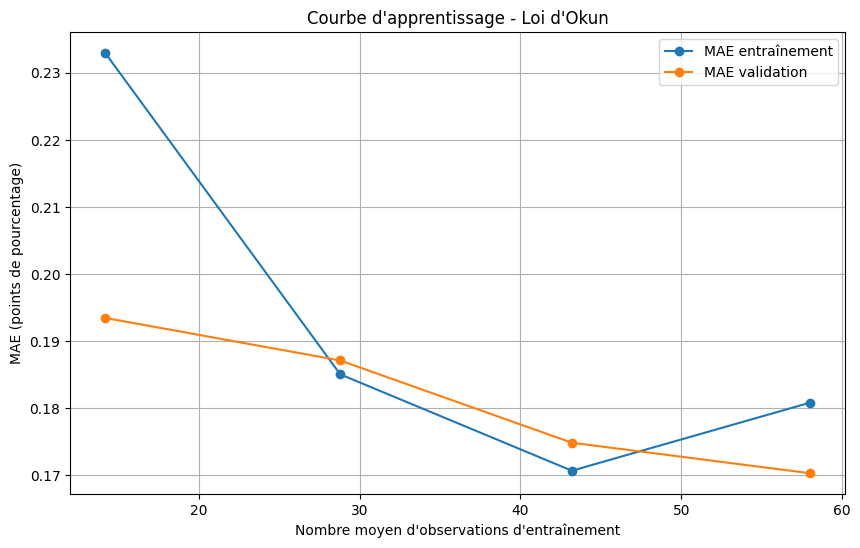

In [157]:

# Importer les outils nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error

# Validation chronologique sur les données d'entraînement uniquement
cv_apprentissage = TimeSeriesSplit(n_splits=5)

# Tailles progressives des échantillons d'entraînement
fractions = [0.25, 0.50, 0.75, 1.00]

resultats = []

# Parcourir les 5 plis chronologiques
for numero_pli, (indices_train, indices_validation) in enumerate(
    cv_apprentissage.split(X_train), start=1
):

    X_validation = X_train.iloc[indices_validation]
    y_validation = y_train.iloc[indices_validation]

    # Tester plusieurs tailles d'entraînement
    for fraction in fractions:

        n = max(5, int(len(indices_train) * fraction))
        n = min(n, len(indices_train))

        X_partiel = X_train.iloc[indices_train[:n]]
        y_partiel = y_train.iloc[indices_train[:n]]

        # Cloner le meilleur Pipeline sélectionné
        modele_temp = clone(modele)
        modele_temp.fit(X_partiel, y_partiel)

        # Calculer les erreurs d'entraînement et de validation
        pred_train = modele_temp.predict(X_partiel)
        pred_validation = modele_temp.predict(X_validation)

        mae_train = mean_absolute_error(y_partiel, pred_train)
        mae_validation = mean_absolute_error(
            y_validation, pred_validation
        )

        resultats.append({
            "Pli": numero_pli,
            "Fraction": fraction,
            "Taille": n,
            "MAE_train": mae_train,
            "MAE_validation": mae_validation
        })

# Regrouper les résultats par taille d'entraînement
resultats_df = pd.DataFrame(resultats)

courbe_apprentissage = (
    resultats_df.groupby("Fraction")
    .agg({
        "Taille": "mean",
        "MAE_train": "mean",
        "MAE_validation": "mean"
    })
    .reset_index()
)

print("Résultats de la courbe d'apprentissage :")
display(courbe_apprentissage.round(4))

# Tracer la courbe
plt.figure(figsize=(10, 6))

plt.plot(
    courbe_apprentissage["Taille"],
    courbe_apprentissage["MAE_train"],
    marker="o",
    label="MAE entraînement"
)

plt.plot(
    courbe_apprentissage["Taille"],
    courbe_apprentissage["MAE_validation"],
    marker="o",
    label="MAE validation"
)

plt.title("Courbe d'apprentissage - Loi d'Okun")
plt.xlabel("Nombre moyen d'observations d'entraînement")
plt.ylabel("MAE (points de pourcentage)")
plt.legend()
plt.grid(True)
plt.show()


**Exemples de prédictions**

In [158]:

# Présenter cinq exemples de prédictions sur les données de test

exemples_predictions = pd.DataFrame({
    "Trimestre": donnees_finales.loc[y_test.index, "trimestre"].astype(str).values,
    "Croissance PIB (%)": X_test["GDP_Growth"].values,
    "Variation chômage réelle": y_test.values,
    "Variation chômage prédite": y_pred_final,
    "Erreur absolue": np.abs(y_test.values - y_pred_final)
})

# Afficher les cinq premières observations du test
print("Exemples de prédictions sur cinq trimestres du test :")
display(exemples_predictions.head(5).round(4))


Exemples de prédictions sur cinq trimestres du test :


,Trimestre,Croissance PIB (%),Variation chômage réelle,Variation chômage prédite,Erreur absolue
0,2019Q1,0.6243,0.0333,-0.0866,0.1200
1,2019Q2,0.8351,-0.2333,-0.1159,0.1174
2,2019Q3,1.1700,-0.0333,-0.1624,0.1290
3,2019Q4,0.6819,0.0000,-0.0946,0.0946
4,2020Q1,-1.3163,0.2333,0.1827,0.0507


**Interprétation des exemples de prédictions**

Les cinq exemples de prédictions permettent de comparer les variations réellement observées du chômage aux valeurs estimées par notre modèle. Les résultats montrent que les prédictions ne correspondent pas parfaitement aux observations réelles. Certains écarts restent importants, ce qui confirme les limites de la régression linéaire simple pour représenter toutes les fluctuations du marché du travail américain.

### Évaluation des performances du modèle


L'évaluation du modèle optimisé sur les 29 observations de test donne une MAE de 0,6199 et une MSE de 2,7676.

Le coefficient de détermination R² est de 0,2579, ce qui signifie que le modèle explique environ 25,79 % de la variance de la variation du taux de chômage sur l'échantillon de test.

La régression optimisée obtient de meilleures performances que la référence naïve, avec une MAE de 0,6199 contre 0,6996. Toutefois, ses performances restent limitées, notamment face aux fluctuations économiques exceptionnelles.


**Comparaison des valeurs réelles et prédites**

*   Les valeurs réellement observées de Delta_UNRATE.

*   Les valeurs prédites par notre modèle de régression linéaire.


**#  Construire le graphique**

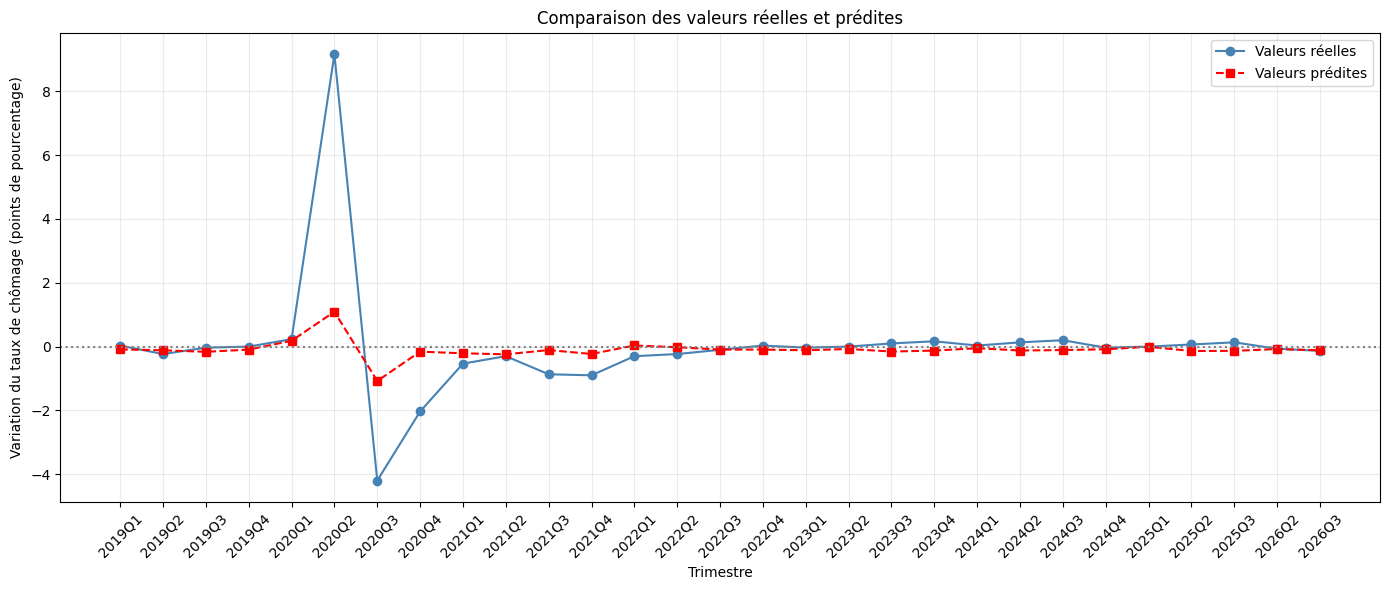

In [159]:
plt.figure(figsize=(14, 6))

# Récupérer les trimestres correspondant aux données de test
periodes_test = donnees_finales.loc[y_test.index, "trimestre"].astype(str)

# Valeurs réelles
plt.plot(
    periodes_test,
    y_test,
    label="Valeurs réelles",
    color="steelblue",
    marker="o",
    linewidth=1.5
)

# Valeurs prédites
plt.plot(
    periodes_test,
    y_pred_final,
    label="Valeurs prédites",
    color="red",
    marker="s",
    linestyle="--",
    linewidth=1.5
)

plt.title("Comparaison des valeurs réelles et prédites")
plt.xlabel("Trimestre")
plt.ylabel("Variation du taux de chômage (points de pourcentage)")

plt.xticks(rotation=45)
plt.axhline(y=0, color="gray", linestyle=":")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Comparaison des valeurs réelles et prédites

La comparaison des valeurs réelles et prédites montre que le modèle reproduit relativement bien certaines variations modérées du taux de chômage, notamment entre 2021 et 2026.

Cependant, des écarts importants apparaissent pendant la crise sanitaire de 2020. Le modèle sous-estime notamment la forte augmentation du chômage, puis sa diminution au trimestre suivant.

Ces résultats montrent que la régression linéaire simple présente des limites dans la représentation des fluctuations économiques exceptionnelles. La croissance du PIB constitue un facteur explicatif important, mais elle ne suffit pas à représenter toute la complexité du marché du travail.

**Analyse critique du modèle**

In [160]:
# Créer un tableau de comparaison
comparaison = pd.DataFrame({
    "Trimestre": donnees_finales.loc[y_test.index, "trimestre"].astype(str),
    "Valeur_reelle": y_test,
    "Valeur_predite": y_pred_final
})

# Calculer les erreurs
comparaison["Erreur"] = (
    comparaison["Valeur_reelle"] - comparaison["Valeur_predite"]
)

comparaison["Erreur_absolue"] = comparaison["Erreur"].abs()

# Afficher les 10 plus grandes erreurs
top_erreurs = comparaison.sort_values(
    by="Erreur_absolue",
    ascending=False
).head(10)

display(top_erreurs)

,Trimestre,Valeur_reelle,Valeur_predite,Erreur,Erreur_absolue
121,2020Q2,9.166667,1.093111,8.073555,8.073555
122,2020Q3,-4.200000,-1.077221,-3.122779,3.122779
123,2020Q4,-2.033333,-0.157305,-1.876028,1.876028
126,2021Q3,-0.866667,-0.108308,-0.758358,0.758358
127,2021Q4,-0.900000,-0.230828,-0.669172,0.669172
128,2022Q1,-0.300000,0.035296,-0.335296,0.335296
124,2021Q1,-0.533333,-0.210049,-0.323284,0.323284
138,2024Q3,0.200000,-0.108120,0.308120,0.308120
135,2023Q4,0.166667,-0.124288,0.290954,0.290954
142,2025Q3,0.133333,-0.132709,0.266042,0.266042


### Analyse des erreurs de prédiction et des observations extrêmes

L'examen des dix plus grandes erreurs de prédiction révèle que les écarts les plus importants se concentrent principalement autour de l'année 2020.

Le trimestre 2020Q2 présente l'erreur absolue la plus élevée, avec environ 6,91 points de pourcentage. Le modèle prédit une augmentation du chômage de 2,26 points, alors que la variation réellement observée atteint 9,17 points.

Des écarts importants apparaissent également en 2020Q3 et 2020Q4. Ces résultats montrent que le modèle a des difficultés à représenter les fluctuations exceptionnelles du marché du travail pendant la crise sanitaire.

Ces observations appartiennent à l'échantillon de test et n'ont donc pas participé à l'estimation initiale des coefficients. Elles mettent néanmoins en évidence les limites prédictives du modèle face aux événements économiques exceptionnels.

**Vérification de la significativité statistique**

**Effectuer un test statistique**

In [161]:

# Importer Statsmodels
import statsmodels.api as sm

# Estimer la régression sans constante,
# conformément au meilleur Pipeline sélectionné
modele_ols = sm.OLS(y_train, X_train).fit()

# Corriger les erreurs-types pour tenir compte
# de l'autocorrélation et de l'hétéroscédasticité
modele_ols_hac = modele_ols.get_robustcov_results(
    cov_type="HAC",
    maxlags=4
)

# Afficher les résultats de l'inférence robuste
print("Résultats de la régression avec erreurs-types HAC :")
print(modele_ols_hac.summary())


Résultats de la régression avec erreurs-types HAC :
                                 OLS Regression Results                                
Dep. Variable:           Delta_UNRATE   R-squared (uncentered):                   0.173
Model:                            OLS   Adj. R-squared (uncentered):              0.165
Method:                 Least Squares   F-statistic:                              13.09
Date:                Tue, 24 Nov 2026   Prob (F-statistic):                    0.000444
Time:                        22:56:30   Log-Likelihood:                         -7.6667
No. Observations:                 115   AIC:                                      17.33
Df Residuals:                     114   BIC:                                      20.08
Df Model:                           1                                                  
Covariance Type:                  HAC                                                  
                 coef    std err          t      P>|t|      [0.025  

**Vérifier la stabilité du coefficient**

In [162]:

# Vérifier la stabilité du coefficient sur deux sous-périodes

from sklearn.base import clone

# Diviser chronologiquement les données d'entraînement en deux
milieu = len(X_train) // 2

# Première sous-période
X_periode1 = X_train.iloc[:milieu]
y_periode1 = y_train.iloc[:milieu]

# Deuxième sous-période
X_periode2 = X_train.iloc[milieu:]
y_periode2 = y_train.iloc[milieu:]

# Entraîner le même modèle sur chaque sous-période
modele_periode1 = clone(modele)
modele_periode1.fit(X_periode1, y_periode1)

modele_periode2 = clone(modele)
modele_periode2.fit(X_periode2, y_periode2)

# Récupérer les coefficients
coef1 = modele_periode1.named_steps["regression"].coef_[0]
coef2 = modele_periode2.named_steps["regression"].coef_[0]

# Identifier les périodes correspondantes
trimestres_train = donnees_finales.loc[
    X_train.index, "trimestre"
].astype(str)

# Construire le tableau de stabilité
stabilite = pd.DataFrame({
    "Sous-période": ["Première moitié", "Deuxième moitié"],
    "Début": [
        trimestres_train.iloc[0],
        trimestres_train.iloc[milieu]
    ],
    "Fin": [
        trimestres_train.iloc[milieu - 1],
        trimestres_train.iloc[-1]
    ],
    "Coefficient": [coef1, coef2]
})

print("Analyse de la stabilité du coefficient :")
display(stabilite.round(4))

print(
    "Écart absolu entre les coefficients :",
    round(abs(coef2 - coef1), 4)
)


Analyse de la stabilité du coefficient :


,Sous-période,Début,Fin,Coefficient
0,Première moitié,1990Q2,2004Q2,-0.0718
1,Deuxième moitié,2004Q3,2018Q4,-0.2380


Écart absolu entre les coefficients : 0.1662


### Interprétation de la stabilité du coefficient

L'analyse de stabilité montre que le coefficient de croissance du PIB est négatif sur les deux sous-périodes étudiées. Il passe de −0,0718 entre 1990Q2 et 2004Q2 à −0,2380 entre 2004Q3 et 2018Q4. Cette différence indique que l'intensité de la relation inverse entre la croissance économique et la variation du chômage a évolué au cours du temps. La relation reste cohérente avec le principe de la loi d'Okun, mais son intensité n'est pas parfaitement stable.

**Vérifier l'autocorrélation des résidus**

In [163]:
from statsmodels.stats.diagnostic import acorr_breusch_godfrey

# Test de Breusch-Godfrey avec 4 retards trimestriels
bg_test = acorr_breusch_godfrey(modele_ols, nlags=4)

print("Statistique LM :", bg_test[0])
print("P-value LM :", bg_test[1])
print("Statistique F :", bg_test[2])
print("P-value F :", bg_test[3])

Statistique LM : 53.30880428830172
P-value LM : 7.343523759353178e-11
Statistique F : 18.79405935654274
P-value F : 8.930037592741559e-12


/tmp/ipykernel_11759/3442837168.py:4: FutureWarning: acorr_breusch_godfrey currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  bg_test = acorr_breusch_godfrey(modele_ols, nlags=4)


### Interprétation du test d'autocorrélation

Le test de Breusch-Godfrey, réalisé avec quatre retards trimestriels, donne une statistique LM de 53,3088 avec une p-value de 7,34 × 10⁻¹¹. La statistique F est de 18,7941, avec une p-value de 8,93 × 10⁻¹². Ces deux probabilités étant inférieures au seuil de 1 %, l'hypothèse nulle d'absence d'autocorrélation des résidus est rejetée. Les erreurs du modèle présentent donc une dépendance temporelle. Pour tenir compte de cette caractéristique dans l'inférence statistique, nous avons utilisé des erreurs-types robustes HAC. Cette correction améliore la fiabilité des tests statistiques, mais ne supprime pas l'autocorrélation des résidus.

## 9. Conclusion générale

Cette étude met en évidence une relation négative entre la croissance économique et la variation du chômage aux États-Unis, conformément au principe de la loi d'Okun.

La régression linéaire optimisée présente un coefficient de −0,1388 et explique 25,79 % de la variance sur les données de test. Elle obtient une MAE de 0,6199, meilleure que celle de la référence naïve (0,6996).

Cependant, la relation varie dans le temps et le test de Breusch-Godfrey révèle une autocorrélation des résidus. Les résultats montrent ainsi que la croissance économique contribue à expliquer l'évolution du chômage, mais ne suffit pas à elle seule à rendre compte de toutes ses fluctuations.

## 10. Références et reproduction

### 10.1 Sources des données

Les données utilisées dans cette étude proviennent de la base **FRED (Federal Reserve Economic Data)** de la Federal Reserve Bank of St. Louis.

- **PIB réel des États-Unis (GDPC1)** : https://fred.stlouisfed.org/series/GDPC1
- **Taux de chômage américain (UNRATE)** : https://fred.stlouisfed.org/series/UNRATE

Les deux séries ont été utilisées pour étudier la relation entre la croissance économique et la variation du chômage aux États-Unis sur la période retenue.

**Date d'extraction des données :** 20 novembre 2026.

### 10.2 Ressources méthodologiques

- Documentation officielle de pandas : https://pandas.pydata.org/docs/
- Documentation officielle de scikit-learn : https://scikit-learn.org/stable/
- Documentation officielle de statsmodels : https://www.statsmodels.org/stable/

### 10.3 Dépôt GitHub

Le code source, les données préparées et les documents du projet sont disponibles ici :

https://github.com/bakary289/26006200-BAKARY-TRAORE-FIN-G3


### 10.4 Procédure de reproduction des résultats

Pour reproduire cette étude, il convient de suivre les étapes suivantes :

1. Accéder au dépôt GitHub du projet et télécharger ou cloner les fichiers.
2. Vérifier la présence des données brutes et préparées dans les dossiers correspondants.
3. Installer les bibliothèques Python indiquées dans le fichier `requirements.txt`.
4. Ouvrir le notebook `F16_Loi_Okun_USA.ipynb` dans Google Colab.
5. Exécuter les cellules dans l'ordre chronologique, de la préparation des données jusqu'à l'évaluation du modèle.

Cette procédure permet de reproduire les traitements statistiques, la validation chronologique, l'estimation de la régression et les graphiques présentés dans cette étude.